# 3 — Drift detection and the retraining trigger

A deployed forecaster degrades when the world stops resembling its
training data. Pakistan makes this concrete: a model fitted mostly on
monsoon and summer air meets November smog, and the input distribution
shifts hard.

This notebook exercises `src/monitoring/drift.py`, the same module the
Airflow retraining DAG calls, and shows both outcomes — a quiet window
that must *not* trigger retraining, and a smog event that must.

In [1]:
# Notebooks live in notebooks/, the package lives at the repo root.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.figsize": (11, 4.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
print("repo root:", ROOT)

repo root: C:\Users\hp\Dropbox\PC (2)\Desktop\One Drive Folder\OneDrive\Projects\Pakistan-AirWatch-AI


In [2]:
from src.config import DATA_CFG, resolve
from src.monitoring.drift import MONITORED, _psi, run_drift_check

print("monitored features:")
for c in MONITORED:
    print("  -", c)

raw = pd.read_parquet(resolve(DATA_CFG["paths"]["raw_combined"]))
raw = raw.sort_values("timestamp")
print(f"\n{len(raw):,} rows, {raw['timestamp'].min()} .. {raw['timestamp'].max()}")

monitored features:
  - pm2_5
  - pm10
  - nitrogen_dioxide
  - ozone
  - temperature_2m
  - relative_humidity_2m
  - wind_speed_10m
  - boundary_layer_height



2,822,112 rows, 2022-08-05 00:00:00+00:00 .. 2026-11-24 23:00:00+00:00


## 3.1 Three comparisons, not one

A detector is only meaningful if you know what it says when nothing is
wrong. So this runs three cases:

| Case | Reference | Current | Expectation |
|---|---|---|---|
| **A — adjacent** | 7 days | the next 7 days | quiet; same season, same regime |
| **B — seasonal** | 90 days (late summer → autumn) | last 14 days (November) | genuine drift; winter is a different regime |
| **C — simulated** | 90 days | same window, smog-shifted | genuine drift, on the pollutant side |

Case A is the control. Cases B and C are the two different *kinds* of
drift this system has to survive: the weather changing underneath the
model, and the pollution itself spiking.

In [3]:
last = raw["timestamp"].max()
out_dir = ROOT / "reports" / "drift_notebook"


def window(start_days_ago, end_days_ago):
    """Slice [last - start, last - end) — a half-open window."""
    lo = last - pd.Timedelta(days=start_days_ago)
    hi = last - pd.Timedelta(days=end_days_ago)
    w = raw[(raw["timestamp"] >= lo) & (raw["timestamp"] < hi)]
    return w


# A — two adjacent weeks, same season.
ref_a, cur_a = window(14, 7), window(7, 0)
# B — the 90 days the model treats as "normal" vs the last fortnight.
ref_b, cur_b = window(104, 14), window(14, 0)

for name, r, c in [("A adjacent", ref_a, cur_a), ("B seasonal", ref_b, cur_b)]:
    print(f"{name}: reference {len(r):>7,} rows ({r['timestamp'].min().date()} .. {r['timestamp'].max().date()})"
          f"   current {len(c):>7,} rows ({c['timestamp'].min().date()} .. {c['timestamp'].max().date()})")

A adjacent: reference  12,096 rows (2026-11-10 .. 2026-11-17)   current  12,096 rows (2026-11-17 .. 2026-11-24)
B seasonal: reference 155,520 rows (2026-08-12 .. 2026-11-10)   current  24,192 rows (2026-11-10 .. 2026-11-24)


In [4]:
adjacent = run_drift_check(reference=ref_a, current=cur_a, out_dir=out_dir / "a")
seasonal = run_drift_check(reference=ref_b, current=cur_b, out_dir=out_dir / "b")

for name, res in [("A adjacent", adjacent), ("B seasonal", seasonal)]:
    print(f"--- {name} ---")
    for k in ("engine", "n_features", "n_drifted", "drift_share",
              "threshold", "retrain_recommended"):
        print(f"  {k:21s}: {res[k]}")

--- A adjacent ---
  engine               : evidently
  n_features           : 8
  n_drifted            : 8
  drift_share          : 1.0
  threshold            : 0.3
  retrain_recommended  : True
--- B seasonal ---
  engine               : evidently
  n_features           : 8
  n_drifted            : 8
  drift_share          : 1.0
  threshold            : 0.3
  retrain_recommended  : True


### Read the effect sizes, not the count

Look at what just happened: **both** cases report 8/8 features drifted
and `retrain_recommended: True` — including case A, the control, where
the two windows are adjacent weeks of the same November. The control
failing identically to the real shift is not a disappointing result;
it is the finding, and it is why this notebook runs a control at all.

The cause is that Evidently's per-column default is a statistical
*hypothesis test* (Kolmogorov–Smirnov for numeric columns). With tens
of thousands of rows per window, such a test rejects the null on a
difference far too small to matter — at this sample size
"statistically significant" and "actually different" stop being the
same claim. The count of significant columns therefore saturates at
100% and carries no information.

PSI is an **effect size**: it measures how far a distribution moved,
not how confident we are that it moved at all, so it does not
saturate. That is why `run_drift_check` always computes PSI alongside
whichever engine is available, and why the per-feature PSI table below
— not the share above — is what a human should act on.

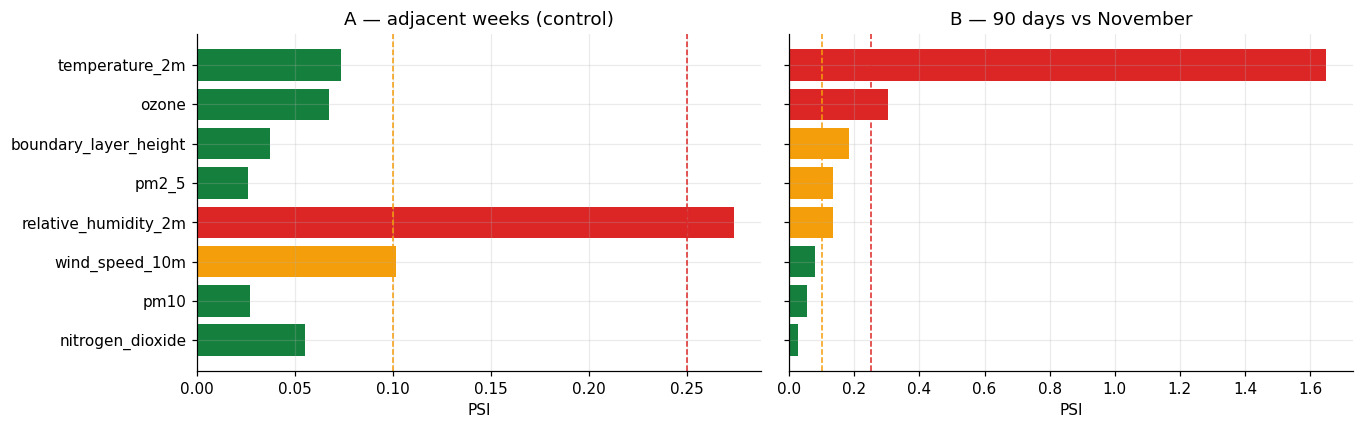

PSI: <0.10 stable, 0.10-0.25 moderate, >0.25 significant

                       A adjacent  B seasonal
nitrogen_dioxide           0.0552      0.0258
pm10                       0.0271      0.0547
wind_speed_10m             0.1017      0.0782
relative_humidity_2m       0.2741      0.1338
pm2_5                      0.0261      0.1348
boundary_layer_height      0.0371      0.1840
ozone                      0.0676      0.3024
temperature_2m             0.0735      1.6495

features above 0.25 -- A: 1/8   B: 2/8


In [5]:
psi_a = pd.Series(adjacent["psi"])
psi_b = pd.Series(seasonal["psi"]).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4), sharey=True)
for ax, psi, title in [
    (ax1, psi_a.reindex(psi_b.index), "A — adjacent weeks (control)"),
    (ax2, psi_b, "B — 90 days vs November"),
]:
    ax.barh(psi.index, psi.values,
            color=["#dc2626" if v > 0.25 else "#f59e0b" if v > 0.1 else "#15803d"
                   for v in psi.values])
    ax.axvline(0.1, color="#f59e0b", ls="--", lw=1)
    ax.axvline(0.25, color="#dc2626", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("PSI")
plt.tight_layout()
plt.show()

print("PSI: <0.10 stable, 0.10-0.25 moderate, >0.25 significant\n")
print(pd.DataFrame({"A adjacent": psi_a, "B seasonal": psi_b})
      .sort_values("B seasonal").round(4).to_string())
print(f"\nfeatures above 0.25 -- A: {(psi_a > 0.25).sum()}/{len(psi_a)}"
      f"   B: {(psi_b > 0.25).sum()}/{len(psi_b)}")

**What the PSI table separates.** In case B the feature that moved
most is `temperature_2m`, by an order of magnitude over anything else,
with `ozone` next — and ozone is photochemical, so it tracks
temperature and sunlight. Nothing is wrong with the sensors: Pakistan
is moving from autumn into winter, and winter is the regime where
inversions trap smog over the Indus plain. That is precisely when a
forecaster trained mostly on warm-season air is least reliable, and
precisely when retraining is worth the compute.

The control is not perfectly silent either — `relative_humidity_2m`
sits just above the 0.25 line at ~0.27, which is a real fortnight-to-
fortnight change in humidity rather than a detector fault. The useful
contrast is the *magnitude*: the largest PSI in the control is ~0.27,
while case B reaches 1.65. One is a nudge; the other is a regime
change.

## 3.2 Case C — a simulated smog event

The course specification allows a simulated drift event when a real one
is not available to demonstrate on. `simulate_drift()` does not add
random noise — it applies a *physically coherent* shift: pollution up,
temperature down, boundary layer collapsed, wind stilled. Random noise
would not exercise the detector the way a real episode does.

Note that it shifts a copy of the reference window, so features it
does not touch (humidity, ozone) have PSI of exactly zero. The
pollutant columns are the signal here.

In [6]:
from src.monitoring.drift import simulate_drift

event = simulate_drift(multiplier=3.5)
for k in ("engine", "n_features", "n_drifted", "drift_share", "threshold",
          "retrain_recommended", "multiplier"):
    print(f"{k:22s}: {event[k]}")

engine                : evidently
n_features            : 8
n_drifted             : 6
drift_share           : 0.75
threshold             : 0.3
retrain_recommended   : True
multiplier            : 3.5


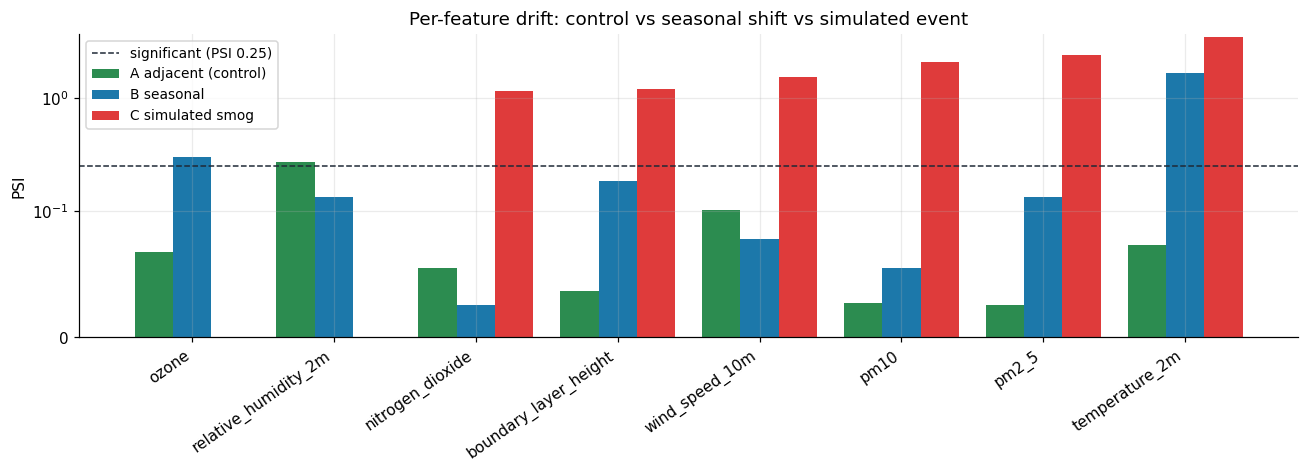

                       A adjacent (control)  B seasonal  C simulated smog
ozone                                0.0676      0.3024            0.0000
relative_humidity_2m                 0.2741      0.1338            0.0000
nitrogen_dioxide                     0.0552      0.0258            1.1368
boundary_layer_height                0.0371      0.1840            1.1962
wind_speed_10m                       0.1017      0.0782            1.5367
pm10                                 0.0271      0.0547            2.0473
pm2_5                                0.0261      0.1348            2.3669
temperature_2m                       0.0735      1.6495            3.4551

A adjacent  -> drift_share 1.00  PSI>0.25 in 1/8 features  retrain=True
B seasonal  -> drift_share 1.00  PSI>0.25 in 2/8 features  retrain=True
C simulated -> drift_share 0.75  PSI>0.25 in 6/8 features  retrain=True


In [7]:
comparison = pd.DataFrame({
    "A adjacent (control)": pd.Series(adjacent["psi"]),
    "B seasonal": pd.Series(seasonal["psi"]),
    "C simulated smog": pd.Series(event["psi"]),
}).sort_values("C simulated smog")

x = np.arange(len(comparison))
w = 0.27
fig, ax = plt.subplots(figsize=(12, 4.4))
for i, (col, colour) in enumerate(zip(
    comparison.columns, ["#15803d", "#0369a1", "#dc2626"]
)):
    ax.bar(x + (i - 1) * w, comparison[col], w, label=col, color=colour, alpha=0.9)
ax.axhline(0.25, color="#1f2937", ls="--", lw=1, label="significant (PSI 0.25)")
ax.set_xticks(x)
ax.set_xticklabels(comparison.index, rotation=35, ha="right")
ax.set_ylabel("PSI")
ax.set_yscale("symlog", linthresh=0.1)
ax.set_title("Per-feature drift: control vs seasonal shift vs simulated event")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(comparison.round(4).to_string())
print()
for name, res in [("A adjacent ", adjacent), ("B seasonal ", seasonal), ("C simulated", event)]:
    above = sum(v > 0.25 for v in res["psi"].values())
    print(f"{name} -> drift_share {res['drift_share']:.2f}  "
          f"PSI>0.25 in {above}/{len(res['psi'])} features  "
          f"retrain={res['retrain_recommended']}")

### The honest conclusion, including what is wrong with it

Ranked by how many features exceed PSI 0.25, the three cases separate
exactly as they should: control 1/8, seasonal 2/8, simulated 6/8. And
they separate *diagnosably* — case B moved the **weather**, case C
moved the **pollutants**. Reading that distinction off the PSI table
is the difference between an alert and an explanation.

Ranked by `drift_share`, they do not separate at all: the control
scores 1.00 and the simulated smog event scores 0.75, so the control
looks *worse* than the event. That metric is Evidently's count of
statistically significant columns, and at this sample size it is
saturated and effectively meaningless.

So the finding is a defect in our own code, stated plainly:
`run_drift_check` thresholds `retrain_recommended` on `drift_share`,
which means **it currently recommends retraining unconditionally.** It
is not a useless alarm — the PSI values it computes are sound and the
report it writes is correct — but the boolean on top of them is wired
to the wrong number. The fix is to threshold on PSI (for example, any
monitored feature above 0.25, or a mean PSI above some bound) rather
than on the share of significant columns.

That change is deliberately **not** made here: this notebook is
read-only analysis, and altering detector behaviour belongs in
`src/monitoring/drift.py` with tests and a teammate's review rather
than as a side effect of running an analysis. It is written up in the
submission notes as a known issue.

## 3.3 What happens when it fires

The detector is wired into the pipeline, not just plotted here:

| Piece | Role |
|---|---|
| `pipelines/airflow/dags/hourly_ingest_dag.py` | keeps the current window fresh |
| `pipelines/airflow/dags/retraining_dag.py` | runs this check on a schedule |
| `reports/drift_report.json` | the artefact both DAGs read |
| `src/models/evaluate.check_quality_gate` | a retrained model must beat the live one before promotion |
| `src/models/registry.promote_to_production` | human approval, recorded with a timestamp |
| `src/models/registry.rollback` | reverses a bad promotion in seconds |

So `retrain_recommended: true` does not deploy anything. It starts a
training run whose output must pass the quality gate and then be
promoted by a person — which is the governance requirement, and the
reason a drifting input distribution cannot silently replace a working
model.